In [ ]:
import csv
import math
import pandas as pd
from google.colab import drive

drive.mount('/gdrive')

def load_data(file_name):
    dataset = []
    with open(file_name, 'r', encoding='utf-8') as f:
        # Sử dụng DictReader để gọi tên cột cho chính xác
        reader = csv.DictReader(f)
        for row in reader:
            # Lấy nội dung từ cột cleaned_website_text và tách từ
            words = row['cleaned_website_text'].lower().split()
            if words: # Chỉ thêm nếu dòng có nội dung
                dataset.append(words)
    return dataset

df = pd.read_excel('/gdrive/MyDrive/btl_khaipha/website_classification1.csv')
df.head()

Mounted at /gdrive


,Unnamed: 0,website_url,cleaned_website_text
0,0,https://www.booking.com/index.html?aid=1743217,official site good hotel accommodation big sav...
1,1,https://travelsites.com/expedia/,expedia hotel book sites like use vacation wor...
2,2,https://travelsites.com/tripadvisor/,tripadvisor hotel book sites like previously d...
3,3,https://www.momondo.in/?ispredir=true,cheap flights search compare flights momondo f...
4,4,https://www.ebookers.com/?AFFCID=EBOOKERS-UK.n...,bot create free account create free account si...


#Tiền xử lý dữ liệu

In [ ]:
#hiển thị bao quát số liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1426 entries, 0 to 1425
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Unnamed: 0            1426 non-null   object
 1   website_url           1425 non-null   object
 2   cleaned_website_text  1408 non-null   object
dtypes: object(3)
memory usage: 33.6+ KB


In [ ]:
df.shape

(1426, 3)

In [ ]:
df['cleaned_website_text'].value_counts()

cleaned_website_text
good multispecialty hospital hyderabad india care hospitals think health think care good hospital hyderabad multi specialty healthcare provider india hospital offer speciality state book appointment book appointment surgical medical radiation bmt complete cancer care tele video consultation comfort home book online appointment care home suraksha plan initiative ensure patient mild symptom expert medical care home liver transplant transform india liver care program key specialities cardiac sciences oncology neuro sciences orthopedics vascular surgery nephrology urology laparoscopic bariatric surgery plastic surgery hpb liver transplantation care care hospital care hospital statistics patient testimonials health tips kidney health condition affect kidney harmful effect air pollution human body lifestyle changes liver healthy medical test diagnose heart disease know doctor vishnu swaroop reddy zeena makhija latest news address hospital networks specialities advanced treatment online lab reports media center blog doctors international patient care care story milestones investors care blog accreditations management board directors specialities anesthesiology general medicine ophthalmology cardiac sciences general surgery surgical gastroenterology orthopedics cardiothoracic surgery hematology pediatrics critical care medicine hepato biliary surgery liver transplantation physiotheraphy rehabilitation dentistry lab medicine plastic surgery dermatology laparoscopic bariatric surgery psychiatry dietetics nutrition nephrology pulmonology ent neuro sciences radiology emergency medicine nuclear medicine rheumatology endocrinology obstetrics gynecology urology gastroenterology oncology vascular surgery hospitals hyderabad care super specialty hospital transplant centre banjara hills care super specialty opd centre banjara hills care super specialty hospital hi tech city care super specialty hospital nampally care super specialty hospital musheerabad care multi specialty hospital secunderabad bhubaneswar care super specialty hospital chandrasekharpur nagpur care super specialty hospital wardha road raipur ramkrishna care super specialty hospital pachpedi naka pune galaxy care hospital karve road visakhapatnam visakhapatnam railway new colony care multi specialty hospital trauma centre maharanipeta care super specialty hospital ramnagar speciality clinic transplant advanced treatment book appointment care story milestones investors care blog accreditations management board directors specialities anesthesiology general medicine ophthalmology cardiac sciences general surgery surgical gastroenterology orthopedics cardiothoracic surgery hematology pediatrics critical care medicine hepato biliary surgery liver transplantation physiotheraphy rehabilitation dentistry lab medicine plastic surgery dermatology laparoscopic bariatric surgery psychiatry dietetics nutrition nephrology pulmonology ent neuro sciences radiology emergency medicine nuclear medicine rheumatology endocrinology obstetrics gynecology urology gastroenterology oncology vascular surgery hospital hyderabad care super specialty hospital transplant centre banjara hills care super specialty opd centre banjara hills care super specialty hospital hi tech city care super specialty hospital nampally care super specialty hospital musheerabad care multi specialty hospital secunderabad visakhapatnam visakhapatnam railway new colony care multi specialty hospital trauma centre maharanipeta care super specialty hospital ramnagar care super specialty hospital bhubaneswar care super specialty hospital nagpur ramkrishna care super specialty hospital galaxy care hospital pune speciality clinic transplant advanced treatment online lab reports media center blog doctors international patient care select hospital care super specialty hospital transplant centre banjara hills care super specialty opd centre banjara hills care super specialty hospital hi tech city care super specialty ho

In [ ]:
df['Unnamed: 0'].value_counts()

,count
Unnamed: 0,
1407,1
0,1
1392,1
1391,1
1390,1
...,...
6,1
5,1
4,1


In [ ]:
df['website_url'].value_counts()

,count
website_url,
News,4
https://carehospitals.com/,4
Education,4
https://www.321chat.com/,2
http://qualgorithms.blogspot.com/,2
...,...
https://www.velare.co/,1
https://mlphotofilm.com/,1
https://rmweddingfilms.co.uk/,1


In [ ]:
#xóa cột không cần thiết
df.drop('Unnamed: 0',axis=1,inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1426 entries, 0 to 1425
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   website_url           1425 non-null   object
 1   cleaned_website_text  1408 non-null   object
dtypes: object(2)
memory usage: 22.4+ KB


In [ ]:
#đếm giá trị thiếu
df.isna().sum()

,0
website_url,1
cleaned_website_text,18


In [ ]:
df= df.dropna(subset = ['website_url','cleaned_website_text'])
df.isna().sum()

,0
website_url,0
cleaned_website_text,0


In [ ]:
#kiểm tra kích thước
df.shape

(1408, 2)

In [ ]:
df.duplicated().sum()

np.int64(22)

In [ ]:
df.describe()

,website_url,cleaned_website_text
count,1408,1408
unique,1384,1375
top,https://carehospitals.com/,good multispecialty hospital hyderabad india c...
freq,4,4


In [ ]:
trung_lap = df[df['website_url'].duplicated(keep=False)]
trung_lap
#sắp xếp
trung_lap.sort_values(by=df.columns.tolist())

,website_url,cleaned_website_text
1213,http://qualgorithms.blogspot.com/,quantum algorithms quantum computing blog quan...
1215,http://qualgorithms.blogspot.com/,quantum algorithms quantum computing blog quan...
1167,http://www.americangiftfactory.com/,angel dear blankies animal blankets swaddle de...
1168,http://www.americangiftfactory.com/,angel dear blankies animal blankets swaddle de...
685,http://www.freedomhealthrecovery.com/,freedom health recovery site provide holistic ...
686,http://www.freedomhealthrecovery.com/,freedom health recovery site provide holistic ...
1207,http://www.kasrl.org/jaffe.html,japanese female facial expression jaffe datase...
1298,http://www.kasrl.org/jaffe.html,japanese female facial expression jaffe datase...
744,http://www.oilofpisces.com/,oil pisce fish oil health oil pisces categorie...
746,http://www.oilofpisces.com/,oil pisce fish oil health oil pisces categorie...


In [ ]:
# xóa URL trùng
df = df.drop_duplicates(subset='website_url')

In [ ]:
trung_lap = df[df['cleaned_website_text'].duplicated(keep=False)]
trung_lap
#sắp xếp
trung_lap.sort_values(by=df.columns.tolist())

,website_url,cleaned_website_text
1261,http://www.1lovecards.com/,welcome bluehost rate web host provider free c...
563,http://www.bbc.com/,bbc homepage breaking news sport tv radio lot ...
360,http://www.paltalk.com/,video chat paltalk large video chat room commu...
1211,http://www.panzercad.com/,welcome bluehost rate web host provider free c...
337,https://tinychat.com/,live video chat room simple easy tinychat chat...
552,https://www.bbc.com/,bbc homepage breaking news sport tv radio lot ...
424,https://www.danielkennedy.com,celebrity photographer london dan kennedy dan ...
496,https://www.danielkennedy.com/,celebrity photographer london dan kennedy dan ...
409,https://www.dpreview.com,digital photography review expert news review ...
462,https://www.dpreview.com/,digital photography review expert news review ...


In [ ]:
# xóa text trùng
df = df.drop_duplicates(subset='cleaned_website_text')

In [ ]:
df.describe()

,website_url,cleaned_website_text
count,1373,1373
unique,1373,1373
top,http://www.world-sex-news.com/,world sex news daily sex news adult news eroti...
freq,1,1


In [ ]:
df.shape

(1373, 2)

In [ ]:
texts = df["cleaned_website_text"]
texts

,cleaned_website_text
0,official site good hotel accommodation big sav...
1,expedia hotel book sites like use vacation wor...
2,tripadvisor hotel book sites like previously d...
3,cheap flights search compare flights momondo f...
4,bot create free account create free account si...
...,...
1421,old nude women porn mature granny sex horny ol...
1422,bdsm cams bdsm chat bondage cams free bdsm vid...
1423,porno dvd online european porn dvd cheap adult...
1424,anal dream house anal dream house anal dream h...


#Tiềm xử lý văn bản

In [ ]:
import pandas as pd
import numpy as np
import re
import math
import random
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
from collections import Counter

In [ ]:
print(f"Tổng số website: {len(df)}")
print(f"Các cột: {df.columns.tolist()}")


Tổng số website: 1373
Các cột: ['website_url', 'cleaned_website_text']


In [ ]:
# BƯỚC 1: TIỀN XỬ LÝ VĂN BẢN
#1.1 Danh sách Stopwords tiếng Anh
STOPWORDS = {
    'a','an','the','is','are','was','were','be','been','being',
    'have','has','had','do','does','did','will','would','could',
    'should','may','might','shall','can','need','dare','ought',
    'used','and','but','or','nor','for','yet','so','as','if',
    'in','on','at','to','of','by','up','it','its','this','that',
    'these','those','i','me','my','we','our','you','your','he',
    'she','him','her','they','them','their','what','which','who',
    'whom','how','when','where','why','all','both','each','few',
    'more','most','other','some','such','no','not','only','same',
    'than','too','very','just','also','with','from','about','into',
    'through','during','before','after','above','below','between',
    'out','off','over','under','again','then','once','here','there',
    'any','am','been','get','got','go','make','made','know','use',
    'find','give','take','come','see','think','look','want','seem',
    'feel','try','leave','call','keep','let','put','set','work',
    'like','new','good','great','free','best','top','one','two',
    'three','way','every','much','many','well','back','first',
    'own','right','now','still','even','us','www','http','https',
    'com','org','net','html','site','page','click','read','more',
    'create','account','sign','log','bot','index','ispredir','true',
    'aid','affcid','refid','refclick','locale','alliance','en'
}


In [ ]:
def buoc_1_lowercase(text):
    #Chuyển về chữ thường
    return text.lower()

def buoc_2_remove_special(text):
    #Xóa ký tự đặc biệt, giữ lại chữ cái và khoảng trắng
    text = re.sub(r'[^a-z\s]', ' ', text)   # xóa số và ký tự đặc biệt
    text = re.sub(r'\s+', ' ', text).strip() # chuẩn hóa khoảng trắng
    return text

def buoc_3_tokenize(text):
    #Tokenization - tách từ theo khoảng trắng
    return text.split()

def buoc_4_remove_stopwords(tokens):
    #Xóa stopwords và từ quá ngắn (<= 2 ký tự)
    return [t for t in tokens if t not in STOPWORDS and len(t) > 2]

def tien_xu_ly(text):
    text = buoc_1_lowercase(text)
    text = buoc_2_remove_special(text)
    tokens = buoc_3_tokenize(text)
    tokens = buoc_4_remove_stopwords(tokens)
    return tokens

corpus = [tien_xu_ly(text) for text in df['cleaned_website_text']]
print(f"Tiền xử lý xong {len(corpus)} dòng dữ liệu")
print(f"[VD]  URL: {df['website_url'].iloc[0][:60]}")
print(f"      Tokens mẫu: {corpus[0][:12]} ...")

Tiền xử lý xong 1373 dòng dữ liệu
[VD]  URL: https://www.booking.com/index.html?aid=1743217
      Tokens mẫu: ['official', 'hotel', 'accommodation', 'big', 'saving', 'hotel', 'destination', 'worldwide', 'browse', 'hotel', 'review', 'guarantee'] ...


In [ ]:
# BƯỚC 2: BIỂU DIỄN VĂN BẢN THÀNH VECTOR (TF-IDF)
N = len(corpus)  # số documents

# 2.1 Xây dựng từ điển
word_count_global = Counter()
for tokens in corpus:
    word_count_global.update(set(tokens))  # mỗi doc đếm 1 lần (cho IDF)

# Chỉ giữ những từ xuất hiện ít nhất 5 lần trong corpus (lọc nhiễu)
MIN_DF = 5
vocab_words = [w for w, cnt in word_count_global.items() if cnt >= MIN_DF]
vocab_words = sorted(vocab_words)                     # sắp xếp để ổn định
word2idx = {w: i for i, w in enumerate(vocab_words)} # word → index
V = len(vocab_words)
print(f"Kích thước vocabulary: {V} từ (min_df={MIN_DF})")

#2.2 Tính TF (Term Frequency)
def tinh_tf(tokens, word2idx):
    tf = {}
    total = len(tokens) if tokens else 1
    count = Counter(tokens)
    for word, idx in word2idx.items():
        tf[idx] = count.get(word, 0) / total
    return tf

#2.3 Tính IDF (Inverse Document Frequency)
def tinh_idf(corpus, word2idx, N):
    idf = {}
    for word, idx in word2idx.items():
        df = word_count_global.get(word, 0)
        idf[idx] = math.log(N / (1 + df))
    return idf

idf = tinh_idf(corpus, word2idx, N)

#2.4 Xây dựng ma trận TF-IDF
def build_tfidf_matrix(corpus, word2idx, idf, V):
    matrix = np.zeros((len(corpus), V), dtype=np.float32)
    for i, tokens in enumerate(corpus):
        tf = tinh_tf(tokens, word2idx)
        for idx, tf_val in tf.items():
            matrix[i, idx] = tf_val * idf[idx]
    return matrix

X = build_tfidf_matrix(corpus, word2idx, idf, V)
print(f"Ma trận TF-IDF: {X.shape[0]} x {X.shape[1]}")

#2.5 Chuẩn hóa L2 (Normalize)
def l2_normalize(matrix):
    """Chia mỗi hàng cho norm L2 của nó"""
    norms = np.sqrt((matrix ** 2).sum(axis=1, keepdims=True))
    norms[norms == 0] = 1  # tránh chia 0
    return matrix / norms

X = l2_normalize(X)
print(f"Chuẩn hóa xong")


Kích thước vocabulary: 10537 từ (min_df=5)
Ma trận TF-IDF: 1373 x 10537
Chuẩn hóa xong


#Thuật toán K-means

In [ ]:
# BƯỚC 3: PHÂN CỤM BẰNG K-MEANS
#3.1 Hàm tính khoảng cách Euclidean
def tinh_ma_tran_khoang_cach(X, centroids):
    X_sq = np.sum(X**2, axis=1, keepdims=True)
    C_sq = np.sum(centroids**2, axis=1, keepdims=True).T
    X_C_link = 2 * np.dot(X, centroids.T)
    dist_sq = X_sq + C_sq - X_C_link
    dist_sq = np.maximum(dist_sq, 0) # Tránh số âm cực nhỏ do sai số máy tính
    return np.sqrt(dist_sq)

#3.2 Hàm tính tâm cụm
def tinh_tam_cum(X, labels, k):
    n_features = X.shape[1]
    centroids = np.zeros((k, n_features), dtype=np.float32)
    for c in range(k):
        members = X[labels == c]
        if len(members) > 0:
            centroids[c] = members.mean(axis=0)
        else:
            # Cụm rỗng: chọn ngẫu nhiên một điểm
            centroids[c] = X[random.randint(0, len(X)-1)]
    return centroids

#3.3 Hàm gán nhãn (mỗi điểm → cụm gần nhất)
def gan_nhan(X, centroids):
    """Gán nhãn tối ưu bằng NumPy argmin (Không dùng vòng lặp for từng dòng)"""
    distances = tinh_ma_tran_khoang_cach(X, centroids)
    return np.argmin(distances, axis=1)

#3.4 Hàm tính WCSS (Within-Cluster Sum of Squares)
def tinh_wcss(X, labels, centroids):
    """Tính WCSS tối ưu theo cụm thay vì chạy for qua từng điểm dữ liệu"""
    wcss = 0.0
    for c in range(len(centroids)):
        members = X[labels == c]
        if len(members) > 0:
            diff = members - centroids[c]
            wcss += float(np.sum(diff ** 2))
    return wcss

#3.5 Thuật toán K-Means chính
def kmeans(X, k, max_iter=100, n_init=3, seed=42):
    random.seed(seed)
    np.random.seed(seed)
    best_labels, best_centroids, best_wcss = None, None, float('inf')

    for trial in range(n_init):
        # --- Tối ưu hóa Khởi tạo K-Means++ ---
        centroids = []
        first_idx = random.randint(0, len(X) - 1)
        centroids.append(X[first_idx].copy())

        for _ in range(k - 1):
            C_arr = np.array(centroids, dtype=np.float32)
            # Tính khoảng cách từ tất cả các điểm đến các tâm cụm hiện tại
            dist_matrix = tinh_ma_tran_khoang_cach(X, C_arr)
            # Lấy khoảng cách ngắn nhất của mỗi điểm tới tâm gần nhất
            min_distances = np.min(dist_matrix, axis=1)
            distances_sq = min_distances ** 2

            # Chọn điểm tiếp theo theo xác suất tỷ lệ với d^2
            dist_sum = distances_sq.sum()
            probs = distances_sq / (dist_sum if dist_sum > 0 else 1)
            cumulative = np.cumsum(probs)
            r = random.random()
            next_idx = np.searchsorted(cumulative, r)
            centroids.append(X[next_idx].copy())

        centroids = np.array(centroids, dtype=np.float32)

        # --- Vòng lặp K-Means chính ---
        labels = np.zeros(len(X), dtype=int)
        for iteration in range(max_iter):
            new_labels = gan_nhan(X, centroids)
            new_centroids = tinh_tam_cum(X, new_labels, k) # Giữ nguyên hàm tính tâm cụm của bạn vì đã tối ưu tốt

            if np.array_equal(new_labels, labels):
                break
            labels = new_labels
            centroids = new_centroids

        wcss = tinh_wcss(X, labels, centroids)
        if wcss < best_wcss:
            best_wcss = wcss
            best_labels = labels.copy()
            best_centroids = centroids.copy()

    return best_labels, best_centroids, best_wcss

#Phương pháp ELBOW

In [ ]:
#3.6 PHƯƠNG PHÁP ELBOW để chọn K tối ưu
K_range = range(2, 31)
wcss_list = []

for k in K_range:
    print(f"Đang chạy K = {k} ...", end=' ', flush=True)
    _, _, wcss = kmeans(X, k, max_iter=50, n_init=2, seed=42)
    wcss_list.append(wcss)
    print(f"WCSS = {wcss:.4f}")

Đang chạy K = 2 ... WCSS = 1323.4113
Đang chạy K = 3 ... WCSS = 1313.1073
Đang chạy K = 4 ... WCSS = 1302.7000
Đang chạy K = 5 ... WCSS = 1299.0657
Đang chạy K = 6 ... WCSS = 1293.9522
Đang chạy K = 7 ... WCSS = 1288.4265
Đang chạy K = 8 ... WCSS = 1281.1569
Đang chạy K = 9 ... WCSS = 1279.2175
Đang chạy K = 10 ... WCSS = 1265.3279
Đang chạy K = 11 ... WCSS = 1264.7429
Đang chạy K = 12 ... WCSS = 1255.4003
Đang chạy K = 13 ... WCSS = 1253.6367
Đang chạy K = 14 ... WCSS = 1249.4673
Đang chạy K = 15 ... WCSS = 1245.4640
Đang chạy K = 16 ... WCSS = 1239.5247
Đang chạy K = 17 ... WCSS = 1239.6528
Đang chạy K = 18 ... WCSS = 1236.0741
Đang chạy K = 19 ... WCSS = 1235.4256
Đang chạy K = 20 ... WCSS = 1230.6012
Đang chạy K = 21 ... WCSS = 1226.8950
Đang chạy K = 22 ... WCSS = 1226.6237
Đang chạy K = 23 ... WCSS = 1216.0559
Đang chạy K = 24 ... WCSS = 1224.0926
Đang chạy K = 25 ... WCSS = 1212.7898
Đang chạy K = 26 ... WCSS = 1214.0924
Đang chạy K = 27 ... WCSS = 1207.2533
Đang chạy K = 28 ...

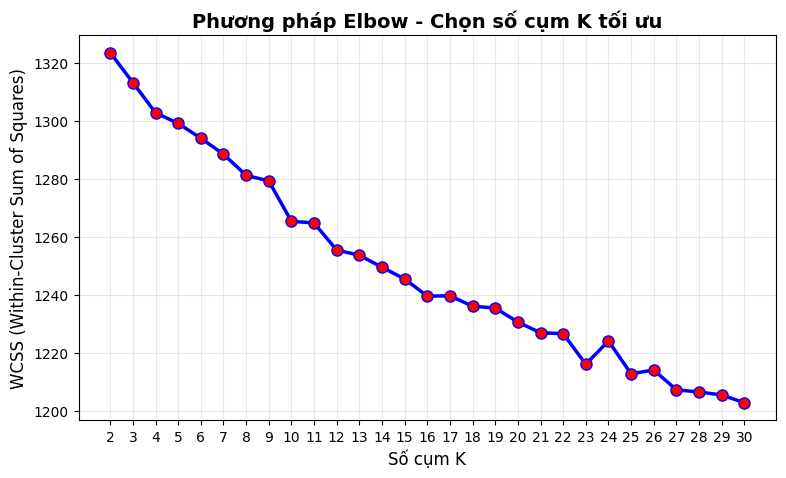

In [ ]:
# Vẽ biểu đồ Elbow
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(K_range), wcss_list, 'bo-', linewidth=2.5, markersize=8, markerfacecolor='red')
ax.set_title('Phương pháp Elbow - Chọn số cụm K tối ưu', fontsize=14, fontweight='bold')
ax.set_xlabel('Số cụm K', fontsize=12)
ax.set_ylabel('WCSS (Within-Cluster Sum of Squares)', fontsize=12)
ax.set_xticks(list(K_range))
ax.grid(True, alpha=0.3)

In [ ]:
# Đánh dấu điểm "khuỷu tay" (elbow)
# Tính bằng phương pháp khoảng cách từ điểm đến đường thẳng nối hai đầu
x_arr = np.array(list(K_range), dtype=float)
y_arr = np.array(wcss_list)
x1, y1 = x_arr[0], y_arr[0]
x2, y2 = x_arr[-1], y_arr[-1]
# Khoảng cách từ mỗi điểm đến đường thẳng nối (x1,y1)-(x2,y2)
distances = []
for i in range(len(x_arr)):
    x0 = x_arr[i]
    y0 = y_arr[i]
    # Công thức khoảng cách điểm đến đường thẳng
    numerator = abs((y2 - y1)*x0 - (x2 - x1)*y0 + x2*y1 - y2*x1)
    denominator = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
    distance = numerator / denominator
    distances.append(distance)
elbow_idx = int(np.argmax(distances[1:-1])+1)
K_optimal = list(K_range)[elbow_idx]

ax.axvline(x=K_optimal, color='green', linestyle='--', linewidth=2, label=f'K tối ưu = {K_optimal}')
ax.annotate(f'Elbow\nK = {K_optimal}',
            xy=(K_optimal, wcss_list[elbow_idx]),
            xytext=(K_optimal + 0.5, wcss_list[elbow_idx] + (max(wcss_list)-min(wcss_list))*0.05),
            fontsize=11, color='green', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='green'))
ax.legend(fontsize=11)
plt.tight_layout()
print(f"K tối ưu được chọn: K = {K_optimal}")


K tối ưu được chọn: K = 12


<Figure size 640x480 with 0 Axes>

In [ ]:
# BƯỚC 4: CHẠY K-MEANS VỚI K TỐI ƯU
final_labels, final_centroids, final_wcss = kmeans(X, K_optimal, max_iter=100, n_init=5, seed=42)
print(f"WCSS cuối: {final_wcss:.4f}")

# Thống kê số website mỗi cụm
cum_count = Counter(final_labels.tolist())
print("Số website trong mỗi cụm:")
for c in sorted(cum_count.keys()):
    print(f"      Cụm {c+1}: {cum_count[c]:4d} websites")

WCSS cuối: 1255.4003
Số website trong mỗi cụm:
      Cụm 1:  610 websites
      Cụm 2:   85 websites
      Cụm 3:   84 websites
      Cụm 4:   51 websites
      Cụm 5:   71 websites
      Cụm 6:   50 websites
      Cụm 7:   43 websites
      Cụm 8:   40 websites
      Cụm 9:   43 websites
      Cụm 10:   43 websites
      Cụm 11:   66 websites
      Cụm 12:  187 websites


In [ ]:
# BƯỚC 5: PHÂN TÍCH & ĐẶT TÊN CỤM
def top_keywords_per_cluster(corpus, labels, word2idx, k, top_n=10):
    idx2word = {i: w for w, i in word2idx.items()}
    cluster_keywords = {}
    for c in range(k):
        # Gộp tất cả tokens trong cụm
        member_indices = [i for i, lbl in enumerate(labels) if lbl == c]
        word_freq = Counter()
        for idx in member_indices:
            word_freq.update(corpus[idx])
        top_words = [w for w, _ in word_freq.most_common(top_n)]
        cluster_keywords[c] = top_words
    return cluster_keywords

cluster_keywords = top_keywords_per_cluster(corpus, final_labels, word2idx, K_optimal)
print()
for c in range(K_optimal):
    count = cum_count[c]
    kw = ', '.join(cluster_keywords[c])
    print(f"  Cụm {c+1:2d} ({count:4d} sites): {kw}")


  Cụm  1 ( 610 sites): home, sex, video, service, time, phone, online, contact, information, live
  Cụm  2 (  85 sites): hotel, travel, flight, tour, view, book, resort, room, day, hotels
  Cụm  3 (  84 sites): december, league, cricket, football, news, team, match, sports, win, world
  Cụm  4 (  51 sites): recipe, recipes, easy, food, chicken, indian, cake, soup, chocolate, pot
  Cụm  5 (  71 sites): game, card, play, player, chess, board, games, hand, pinball, point
  Cụm  6 (  50 sites): photography, camera, photo, photographer, image, dec, light, lens, focus, review
  Cụm  7 (  43 sites): movie, watch, series, drama, season, comedy, show, rate, tvma, action
  Cụm  8 (  40 sites): add, cart, gift, shop, baby, gifts, view, online, love, quality
  Cụm  9 (  43 sites): chat, room, online, people, friend, gay, join, video, meet, teen
  Cụm 10 (  43 sites): shop, online, view, fashion, shoes, product, men, accessories, home, shopping
  Cụm 11 (  66 sites): health, yoga, care, hospital, 

In [ ]:
# BƯỚC 6: LƯU KẾT QUẢ


/tmp/ipykernel_5490/572990445.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', K_optimal)


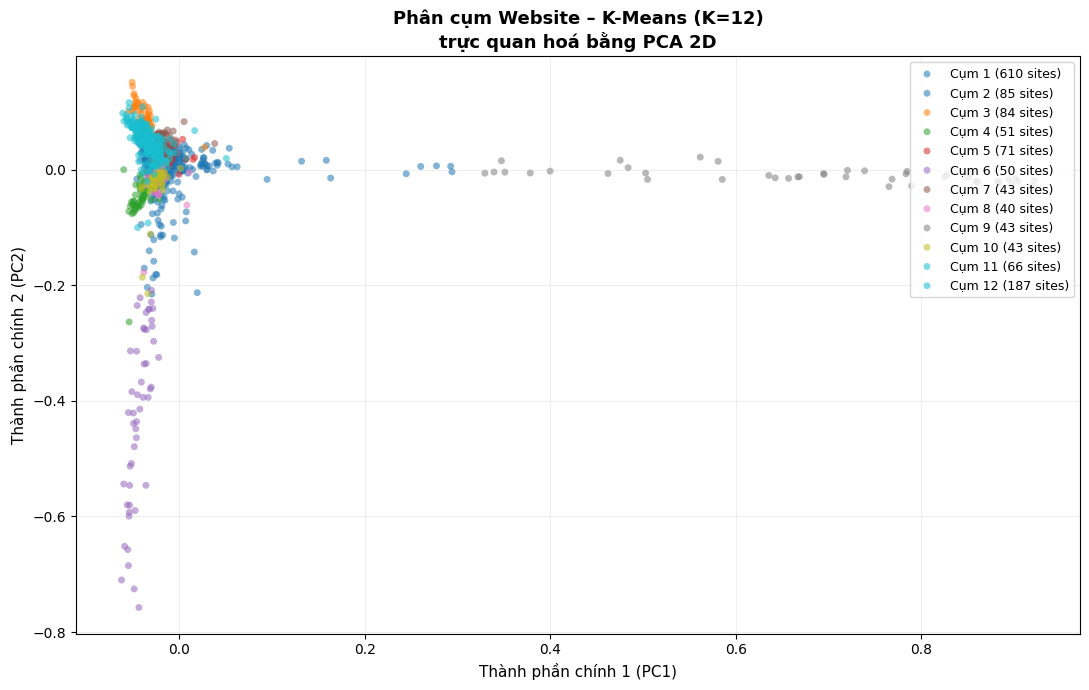

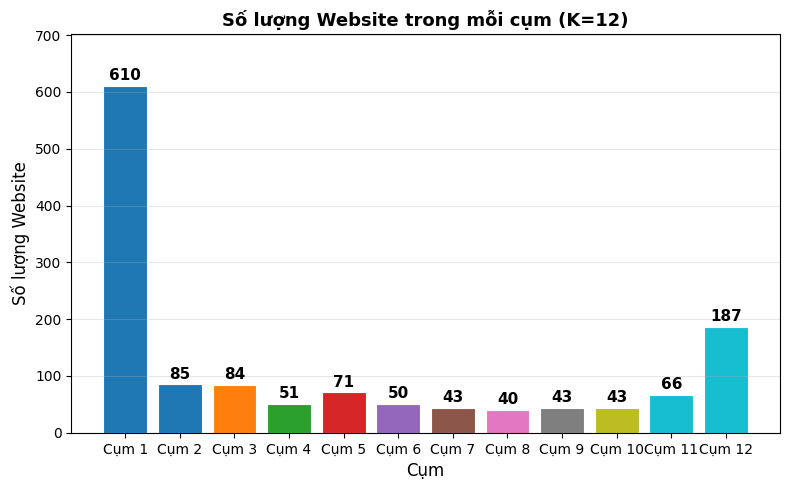

In [ ]:
# BƯỚC 7: VẼ BIỂU ĐỒ PHÂN BỐ CỤM (PCA 2D để trực quan hoá)
def pca_manual(X, n_components=2):
    X_centered = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
    return U[:, :n_components] * S[:n_components]

X_2d = pca_manual(X.astype(np.float64), n_components=2)

colors = plt.cm.get_cmap('tab10', K_optimal)
fig, ax = plt.subplots(figsize=(11, 7))

for c in range(K_optimal):
    mask = final_labels == c
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
               color=colors(c), label=f'Cụm {c+1} ({cum_count[c]} sites)',
               alpha=0.55, s=25, edgecolors='none')

# Vẽ tâm cụm (chiếu cùng Vt)
X_mean = X.astype(np.float64).mean(axis=0)
X_centered = X.astype(np.float64) - X_mean
_, _, Vt = np.linalg.svd(X_centered, full_matrices=False)
centroids_2d = (final_centroids.astype(np.float64) - X_mean) @ Vt[:2].T

ax.set_title(f'Phân cụm Website – K-Means (K={K_optimal})\ntrực quan hoá bằng PCA 2D',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Thành phần chính 1 (PC1)', fontsize=11)
ax.set_ylabel('Thành phần chính 2 (PC2)', fontsize=11)
ax.legend(loc='upper right', fontsize=9, framealpha=0.8)
ax.grid(True, alpha=0.2)
plt.tight_layout()

# Biểu đồ cột số website mỗi cụm
fig2, ax2 = plt.subplots(figsize=(8, 5))
cluster_names = [f'Cụm {c+1}' for c in range(K_optimal)]
cluster_sizes = [cum_count[c] for c in range(K_optimal)]
bar_colors = [colors(c) for c in range(K_optimal)]
bars = ax2.bar(cluster_names, cluster_sizes, color=bar_colors, edgecolor='white', linewidth=0.8)

for bar, size in zip(bars, cluster_sizes):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(size), ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.set_title(f'Số lượng Website trong mỗi cụm (K={K_optimal})', fontsize=13, fontweight='bold')
ax2.set_xlabel('Cụm', fontsize=12)
ax2.set_ylabel('Số lượng Website', fontsize=12)
ax2.set_ylim(0, max(cluster_sizes) * 1.15)
ax2.grid(axis='y', alpha=0.3)
plt.tight_layout()


In [ ]:
print(f"\n  Số website        : {N}")
print(f"  Kích thước vocab  : {V} từ")
print(f"  K tối ưu (Elbow)  : {K_optimal} cụm")
print(f"  WCSS cuối cùng    : {final_wcss:.4f}")


  Số website        : 1373
  Kích thước vocab  : 10537 từ
  K tối ưu (Elbow)  : 12 cụm
  WCSS cuối cùng    : 1255.4003
